# Notebook 03: Quantitative Color & Texture Feature Extraction
**Project:** `Fabric_FYP` — Quantitative Color and Texture Analysis of Degraded Cotton and Polyester Fabrics

This notebook fulfills **Specific Objective 1** by extracting area-normalized, quantitative colorimetric and micro-textural descriptors across the full **30-day exposure period** (15 biennial sampling sessions `D1–D15` at 2-day intervals, plus unexposed Day 0 controls `CC` and `CP`):
* **Color Branch (`data/processed/cropped_roi/`):** Extracts perceptual **CIELAB** coordinates ($L^*, a^*, b^*$), within-ROI spatial color variability ($\sigma_L, \sigma_a, \sigma_b$), **Total Color Difference ($\Delta E_{76}$)** relative to Day 0 fabric controls, and **HSV** descriptors ($H, S, V$).
* **Texture Branch (`data/processed/filtered_texture/`):** Extracts rotation-invariant **Gray-Level Co-occurrence Matrix (GLCM)** statistics, **Uniform Local Binary Pattern (LBP)** entropy/energy metrics, and **Canny Edge Density** from grayscale ROIs (with `3 × 3` median filtering applied to Grade B samples).

In [1]:
import sys
import importlib
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

# Resolve Fabric_FYP project root dynamically
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert PROJECT_ROOT.name == "Fabric_FYP", f"Expected project root 'Fabric_FYP', got '{PROJECT_ROOT.name}'"

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import fabric_taphonomy.features as feat
importlib.reload(feat)  # Always reload latest saved version of features.py
from fabric_taphonomy.features import run_feature_extraction_pipeline

# Define input and output directories
CROPPED_DIR = PROJECT_ROOT / "data" / "processed" / "cropped_roi"
TEXTURE_DIR = PROJECT_ROOT / "data" / "processed" / "filtered_texture"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

manifest_df = pd.read_csv(TABLES_DIR / "preprocessed_manifest.csv")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300})

print(f"Loaded preprocessed manifest: {len(manifest_df)} eligible images ready for feature extraction.")

Loaded preprocessed manifest: 130 eligible images ready for feature extraction.


## 1. Colorimetric & Textural Feature Extraction Pipeline
### A. Colorimetric Descriptors (Unfiltered Adaptive ROIs)
1. **CIELAB Color Space ($L^*, a^*, b^*$):** Designed to approximate human visual perception uniformly:
   * **$L^*$ (`0` to `100`):** Lightness axis; decreases as white fabric darkens due to moisture, UV oxidation, or soil accumulation.
   * **$a^*$ (`-128` to `+127`):** Green-to-red chromaticity axis.
   * **$b^*$ (`-128` to `+127`):** Blue-to-yellow chromaticity axis; increases positively as white cotton or polyester yellows during weathering.
   * **Total Color Difference ($\Delta E_{76}$):** Euclidean color distance between an exposed fabric sample and its corresponding unexposed Day 0 control baseline ($L^*_0, a^*_0, b^*_0$ for `CC` or `CP`):
     $$\Delta E_{76} = \sqrt{(L^* - L^*_0)^2 + (a^* - a^*_0)^2 + (b^* - b^*_0)^2}$$
2. **HSV Color Space ($H, S, V$):** Separates dominant pigment **Hue** ($0^\circ–360^\circ$, computed via circular statistics), **Saturation** ($0–100\%$, capturing optical brightener fading vs. stain chroma), and **Value** ($0–100\%$, surface brightness).

### B. Micro-Textural Descriptors (Grayscale & Grade B Median-Filtered ROIs)
1. **Gray-Level Co-occurrence Matrix (GLCM):** Computed at pixel distance $d = 1$ and averaged across four orientations ($0^\circ, 45^\circ, 90^\circ, 135^\circ$) for rotation invariance:
   * **Contrast:** Local intensity variation between adjacent pixels (increases with fiber pitting, soil roughness, and weave disruption).
   * **Homogeneity:** Closeness of element distribution to the GLCM diagonal (decreases as uniform weave structure degrades).
   * **Energy:** Sum of squared GLCM elements (measures textural order and yarn uniformity).
   * **Correlation:** Linear dependency of gray levels across neighboring threads.
2. **Uniform Local Binary Patterns (LBP, $P = 8, R = 1$):** Encodes local $3 \times 3$ micro-neighborhoods into rotation-invariant uniform structural patterns. **LBP Shannon Entropy** quantifies micro-fibril disorder, whereas **LBP Energy** measures structural regularity.
3. **Canny Edge Density (`canny_edge_pct`):** Percentage of pixels inside the ROI detected as sharp structural edges (`thresholds = 25, 75`), capturing thread fraying and micro-fibril proliferation over time.

In [2]:
# Extract all color and texture features and compute ΔE76 against Day 0 controls
master_df, baseline_df = run_feature_extraction_pipeline(
    manifest_df=manifest_df,
    cropped_dir=CROPPED_DIR,
    texture_dir=TEXTURE_DIR,
    canny_low=25,
    canny_high=75,
)

# Save Day 0 baseline CIELAB references and master feature table
baseline_path = TABLES_DIR / "day0_color_baselines.csv"
master_path = TABLES_DIR / "master_features.csv"

baseline_df.to_csv(baseline_path, index=False)
master_df.to_csv(master_path, index=False)

print("Day 0 Control CIELAB Baselines (CC & CP):")
display(baseline_df)

# Verify zero missing/NaN values and confirm 30-day mapping (D0..D15 -> Day 0..30)
feature_cols = [
    "lab_L_mean", "lab_L_std", "lab_a_mean", "lab_a_std", "lab_b_mean", "lab_b_std",
    "delta_L", "delta_a", "delta_b", "delta_E",
    "hsv_H_deg", "hsv_S_pct", "hsv_V_pct",
    "glcm_contrast", "glcm_homogeneity", "glcm_energy", "glcm_correlation",
    "lbp_entropy", "lbp_energy", "canny_edge_pct"
]
assert not master_df[feature_cols].isna().any().any(), "NaN values detected in extracted features!"
assert master_df["day"].max() == 30, f"Expected max exposure duration of 30 days, got {master_df['day'].max()}"

print(f"\nSuccessfully extracted {len(feature_cols)} features across {len(master_df)} images (Exposure Days: {sorted(master_df['day'].unique())})")
print("Saved master dataset to:", master_path)
display(master_df[["image_id", "fabric", "group_code", "sampling_session", "day", "qc_grade", "delta_E", "delta_b", "glcm_contrast", "lbp_entropy", "canny_edge_pct"]].head(10))

Day 0 Control CIELAB Baselines (CC & CP):


,fabric,control_group,n_controls,baseline_L0,baseline_a0,baseline_b0
0,Cotton,CC,5,86.6245,-10.5304,-11.8643
1,Polyester,CP,5,85.7979,-9.1679,-19.0392



Successfully extracted 20 features across 130 images (Exposure Days: [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(22), np.int64(24), np.int64(26), np.int64(28), np.int64(30)])
Saved master dataset to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/tables/master_features.csv


,image_id,fabric,group_code,sampling_session,day,qc_grade,delta_E,delta_b,glcm_contrast,lbp_entropy,canny_edge_pct
0,C1_D10_8,Cotton,C1,10,20,B,21.2976,21.2771,25.9745,2.2092,15.8640
1,C1_D11_19,Cotton,C1,11,22,B,22.6476,22.6097,19.6798,2.2026,13.4498
2,C1_D12_15,Cotton,C1,12,24,B,22.4785,22.1504,20.2521,2.2771,14.2807
3,C1_D13_4,Cotton,C1,13,26,B,19.3438,19.3249,18.0105,2.2282,12.5700
4,C1_D14_20,Cotton,C1,14,28,B,28.9748,28.5596,25.5168,2.2776,17.4953
5,C1_D15_10,Cotton,C1,15,30,B,29.2631,29.1438,23.0093,2.3838,17.8480
6,C1_D1_1,Cotton,C1,1,2,A,0.9640,-0.7247,3.1211,3.0808,0.0382
7,C1_D2_18,Cotton,C1,2,4,B,4.6087,4.5378,3.3130,2.5442,0.3971
8,C1_D3_16,Cotton,C1,3,6,B,7.8263,7.6954,4.8983,2.4613,0.6483
9,C1_D4_14,Cotton,C1,4,8,B,5.1982,5.1249,4.7397,2.5472,1.3689


## 2. Descriptive Feature Summary Across Experimental Groups
The summary table below presents the mean values of key color ($\Delta E_{76}$, $\Delta b^*$, Saturation) and texture (**GLCM Contrast**, **GLCM Homogeneity**, **LBP Entropy**, **Canny Edge Density**) metrics grouped by fabric type and experimental condition (`Control`, `Indoor`, and `Outdoor Sites 1–3`) to verify directional sensitivity prior to formal statistical hypothesis testing in **Notebook 04**.

In [3]:
summary_metrics = [
    "delta_E", "delta_L", "delta_b", "hsv_S_pct",
    "glcm_contrast", "glcm_homogeneity", "glcm_energy",
    "lbp_entropy", "canny_edge_pct"
]

group_summary = (
    master_df.groupby(["fabric", "setting", "group_code"])[summary_metrics]
    .mean()
    .round(3)
)

display(group_summary)
group_summary.to_csv(TABLES_DIR / "group_feature_means.csv")

delta_E  delta_L  delta_b  hsv_S_pct  \
fabric    setting group_code                                         
Cotton    Control CC            0.704    0.000   -0.000     24.459   
          Indoor  CI            1.115    0.114   -0.100     24.331   
          Outdoor C1           16.274   -0.655   16.068     15.739   
                  C2            6.479    0.139    6.234     18.658   
                  C3           12.651   -1.085   12.373     16.171   
Polyester Control CP            0.891    0.000   -0.000     31.129   
          Indoor  PI            1.101   -0.122    0.063     31.155   
          Outdoor P1           15.599   -0.417   15.478     17.873   
                  P2            6.113   -0.802    5.675     25.912   
                  P3           10.409   -0.584   10.171     21.645   

                              glcm_contrast  glcm_homogeneity  glcm_energy  \
fabric    setting group_code                                                 
Cotton    Control CC                  3.204             0.511        0.095   
          Indoor  CI                  3.218             0.511        0.093   
          Outdoor C1                 15.186             0.379        0.054   
                  C2                  6.306             0.473        0.076   
                  C3                 12.103             0.418        0.061   
Polyester Control CP                  8.831             0.384        0.063   
          Indoor  PI                  8.331             0.394        0.065   
          Outdoor P1                 17.688             0.388        0.052   
                  P2                 10.762             0.425        0.062   
                  P3                 12.943             0.414        0.058   

                              lbp_entropy  canny_edge_pct  
fabric    setting group_code                               
Cotton    Control CC                3.079           0.061  
          Indoor  CI                3.072           0.113  
          Outdoor C1                2.377           9.925  
                  C2                2.694           2.715  
                  C3                2.448           7.567  
Polyester Control CP                3.059           6.497  
          Indoor  PI                3.062           5.754  
          Outdoor P1                2.551          11.770  
                  P2                2.700           8.035  
                  P3                2.603           9.287

## 3. Visual Diagnostic Panel: Spatial Feature Maps & 30-Day Temporal Trends
To demonstrate how each image processing transformation maps physical fabric degradation into quantitative metrics:
1. **Spatial Feature Panel:** Displays a Day 30 (`Session D15`) exposed outdoor fabric ROI alongside its perceptual **$b^*$ yellowing heatmap**, **Uniform LBP micro-pattern map**, and **Canny structural edge detection map**.
2. **Preliminary 30-Day Longitudinal Check:** Plots mean **Total Color Difference ($\Delta E_{76}$)** and **GLCM Contrast** across actual Exposure Days `2` to `30` (2-day sampling intervals) comparing **Cotton vs. Polyester** under **Indoor vs. Outdoor** exposure.

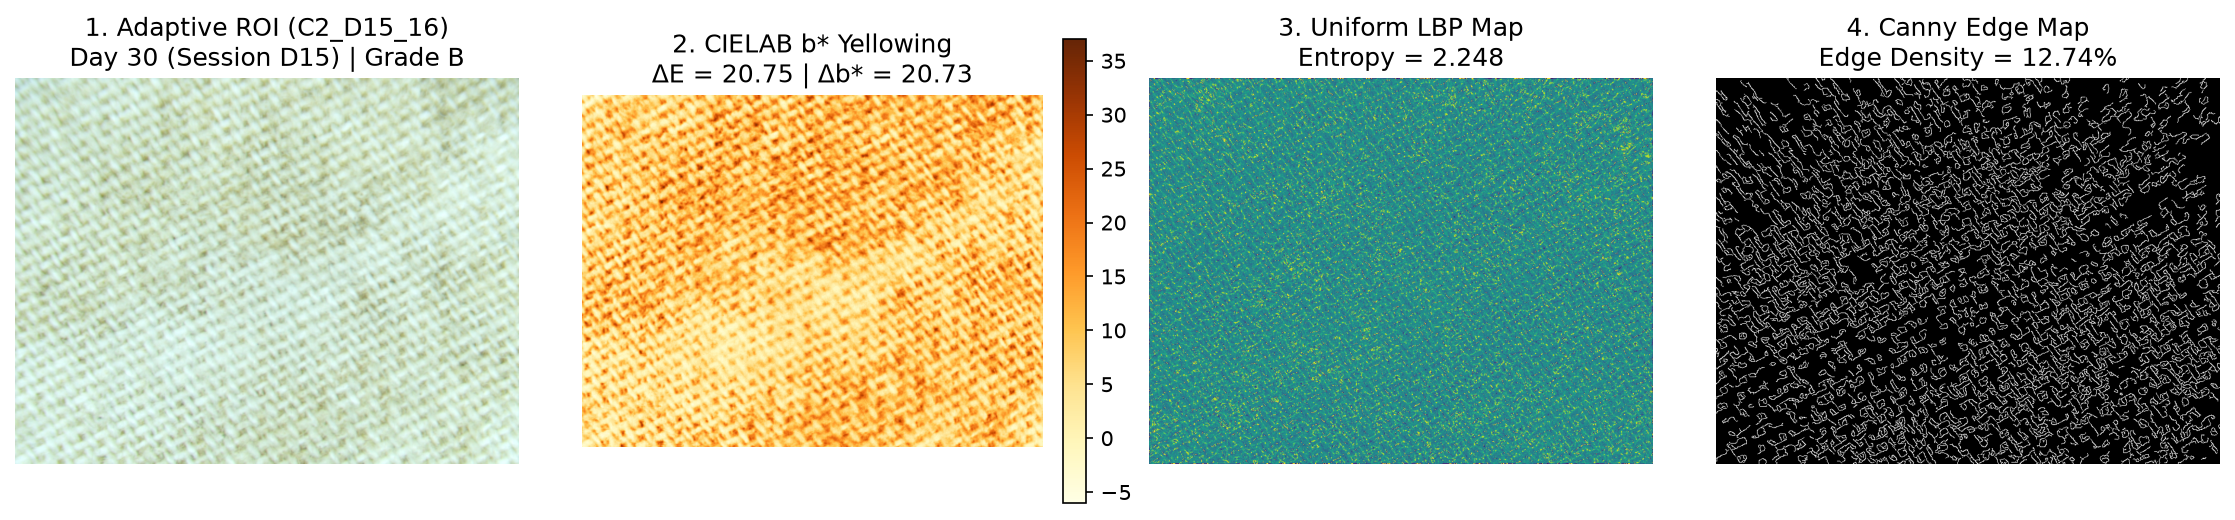

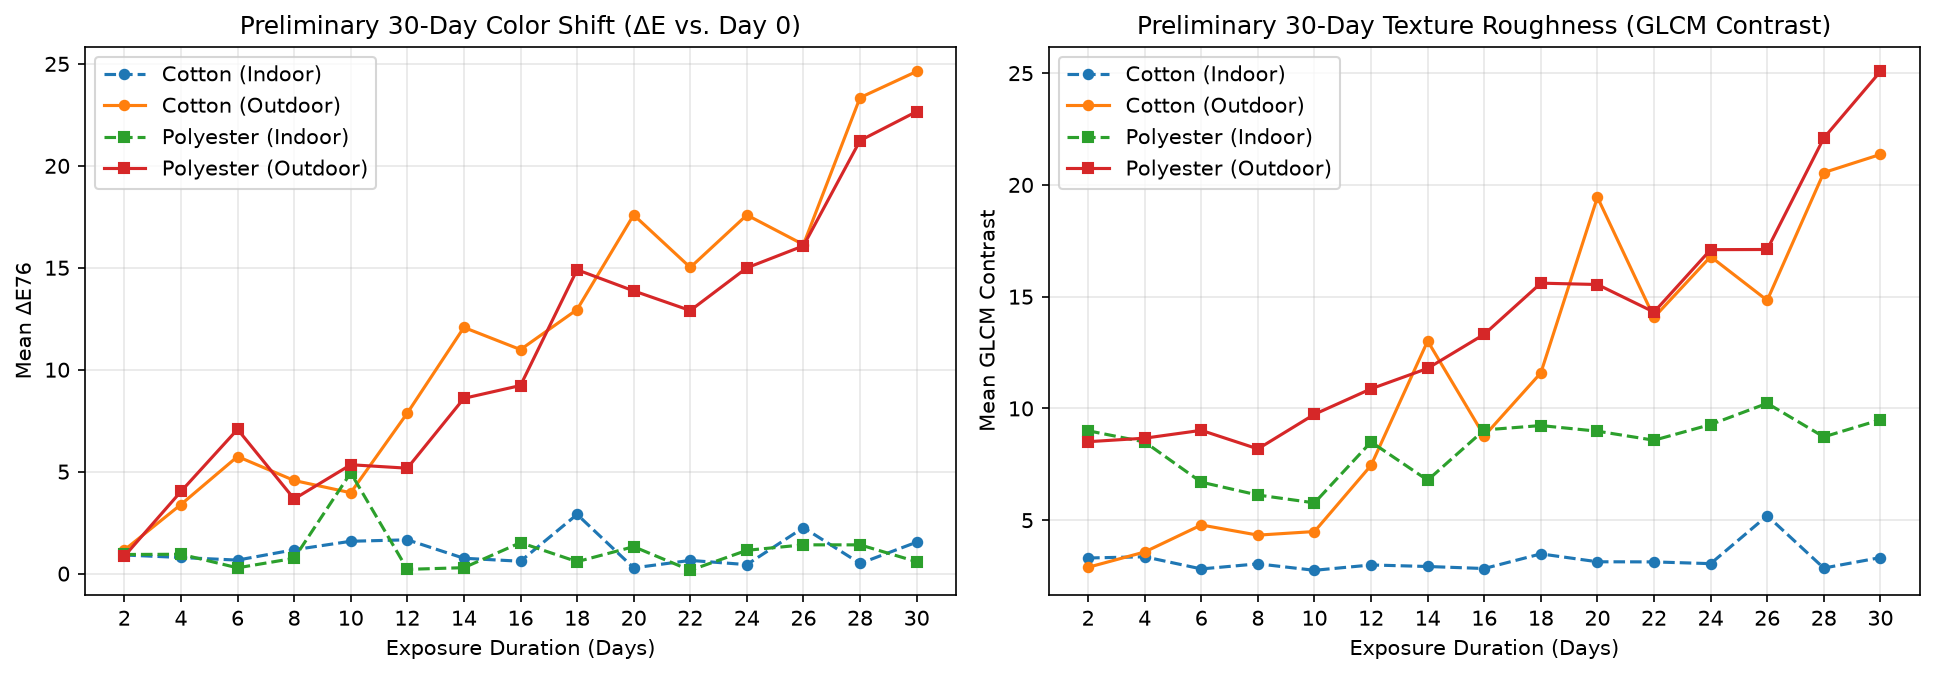

Saved visual diagnostics to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures


In [4]:
# --- Plot 1: 4-Panel Spatial Feature Visualization on a Day 30 (Session D15) Outdoor Cotton Sample ---
outdoor_cot = master_df[(master_df["fabric"] == "Cotton") & (master_df["setting"] == "Outdoor")].sort_values("day", ascending=False)
sample_row = outdoor_cot.iloc[0]

roi_bgr = cv2.imread(str(CROPPED_DIR / sample_row["cropped_rel_path"]))
roi_rgb = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)
tex_gray = cv2.imread(str(TEXTURE_DIR / sample_row["texture_rel_path"]), cv2.IMREAD_GRAYSCALE)

# Compute spatial b* yellowing map, LBP map, and Canny edges for visualization
lab_cv = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
b_map = lab_cv[:, :, 2] - 128.0
lbp_map = local_binary_pattern(tex_gray, P=8, R=1, method="uniform")
canny_map = cv2.Canny(tex_gray, 25, 75)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))

axes[0].imshow(roi_rgb)
axes[0].set_title(f"1. Adaptive ROI ({sample_row['image_id']})\nDay {sample_row['day']} (Session D{sample_row['sampling_session']}) | Grade {sample_row['qc_grade']}")
axes[0].axis("off")

im_b = axes[1].imshow(b_map, cmap="YlOrBr")
axes[1].set_title(f"2. CIELAB b* Yellowing\nΔE = {sample_row['delta_E']:.2f} | Δb* = {sample_row['delta_b']:.2f}")
axes[1].axis("off")
plt.colorbar(im_b, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(lbp_map, cmap="viridis")
axes[2].set_title(f"3. Uniform LBP Map\nEntropy = {sample_row['lbp_entropy']:.3f}")
axes[2].axis("off")

axes[3].imshow(canny_map, cmap="gray")
axes[3].set_title(f"4. Canny Edge Map\nEdge Density = {sample_row['canny_edge_pct']:.2f}%")
axes[3].axis("off")

plt.tight_layout()
map_fig_path = FIGURES_DIR / "spatial_feature_maps.png"
plt.savefig(map_fig_path, dpi=300)
plt.show()

# --- Plot 2: Preliminary 30-Day Temporal Trajectory (ΔE and GLCM Contrast vs. Exposure Days 2..30) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

for (fab, setting), grp in master_df[master_df["setting"].isin(["Indoor", "Outdoor"])].groupby(["fabric", "setting"]):
    daily = grp.groupby("day")[["delta_E", "glcm_contrast"]].mean().reset_index()
    style = "-" if setting == "Outdoor" else "--"
    marker = "o" if fab == "Cotton" else "s"
    label = f"{fab} ({setting})"

    axes[0].plot(daily["day"], daily["delta_E"], linestyle=style, marker=marker, markersize=4.5, label=label)
    axes[1].plot(daily["day"], daily["glcm_contrast"], linestyle=style, marker=marker, markersize=4.5, label=label)

day_ticks = list(range(2, 32, 2))

axes[0].set_title("Preliminary 30-Day Color Shift (ΔE vs. Day 0)")
axes[0].set_xlabel("Exposure Duration (Days)")
axes[0].set_ylabel("Mean ΔE76")
axes[0].set_xticks(day_ticks)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("Preliminary 30-Day Texture Roughness (GLCM Contrast)")
axes[1].set_xlabel("Exposure Duration (Days)")
axes[1].set_ylabel("Mean GLCM Contrast")
axes[1].set_xticks(day_ticks)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
trend_fig_path = FIGURES_DIR / "preliminary_temporal_trends.png"
plt.savefig(trend_fig_path, dpi=300)
plt.show()
print("Saved visual diagnostics to:", FIGURES_DIR)